In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev
import os
import ast
import random

# Add Arial font
import matplotlib.font_manager as fm
fm.fontManager.addfont('/home/scai/phd/aiz217586/.conda/envs/discomat/fonts/arial.ttf')
font_path = "/home/scai/phd/aiz217586/.conda/envs/discomat/fonts/arial.ttf"
arial_font = fm.FontProperties(fname=font_path, size=13)

In [14]:

def plot_gsc(prop_1, prop_2, save_path="gsc_for_all"):
    
    df = pd.read_csv("filtered_no_outliers_2.csv")  # Load the dataframe
#     display(df)

    # Filter the dataframe for the two properties of interest and Elements column
    df_filtered = df[['Proxy_ID', prop_1, prop_2, 'Elements']].copy()
    
    # Remove rows where either property is 0 or NaN
    df_filtered = df_filtered[(df_filtered[prop_1] > 0) & (df_filtered[prop_2] > 0)]
    df_filtered = df_filtered.dropna(subset=[prop_1, prop_2, 'Elements'])
    
    # Parse the Elements column (convert string representation of list to actual list)
    def parse_elements(elements_str):
        try:
            # Handle the string representation of list
            if isinstance(elements_str, str):
                # Remove any extra spaces and parse
                elements_str = elements_str.strip()
                if elements_str.startswith('[') and elements_str.endswith(']'):
                    # Use ast.literal_eval for safe evaluation of list strings
                    return ast.literal_eval(elements_str)
                else:
                    # Handle comma-separated values
                    return [elem.strip().strip("'\"") for elem in elements_str.split(',')]
            elif isinstance(elements_str, list):
                return elements_str
            else:
                return []
        except:
            return []
    
    df_filtered['parsed_elements'] = df_filtered['Elements'].apply(parse_elements)
    
    # Remove rows with empty element lists
    df_filtered = df_filtered[df_filtered['parsed_elements'].apply(len) > 0]
    
    # Define composition families based on the Elements column
    # Sort elements alphabetically to ensure consistent family naming
    df_filtered['family'] = df_filtered['parsed_elements'].apply(lambda x: str(sorted(x)))
    
    # Select the top 10 most frequent composition families
#     top_families = df_filtered['family'].value_counts().head(11)
#     df_top = df_filtered[df_filtered['family'].isin(top_families.index)]
    
    # Convert to DataFrame, sort properly, then back to Series
    family_counts = df_filtered['family'].value_counts()
    family_df = family_counts.reset_index()
    family_df.columns = ['family', 'count']
    family_df = family_df.sort_values(['count', 'family'], ascending=[False, True])
    top_families = family_df.set_index('family')['count'].head(12)
    df_top = df_filtered[df_filtered['family'].isin(top_families.index)]
    
    # Print elements in each family along with frequency
    print("Composition Families and Their Frequency:")
    for family, freq in top_families.items():
        print(f"{family}: {freq} occurrences")
    
    df_top.to_csv(f'{prop_1}_{prop_2}.csv')


    #Colorblind-friendly colors
    colors = [
        "#7AE43F",  # Orange (Family 1)
        "#F0E442",  # Bright Yellow (Family 4)
        "#C556A4",  # Reddish Purple (Family 7)
        "#009E73",  # Bluish Green (Family 3, unchanged)
        "#D55E00",  # Vermillion (Family 6)
        "#56B4E9",  # Sky Blue (Family 5)
        "#EFB4B3",  # Wine Red (Family 2)
        "#b3bfd1",  # Grey (Family 8) 
        "#897FF1",  # Dark Purple (Family 10)
        "#E69F00",  # Saddle Brown (Family 9)
        "#ff80ff",
        "#40E0D0", 
        "#999999",   
    ] #tc_ea, tg_ea, den_sf, tg_tm, tm_tc 
    
#     colors = [
#         "#7AE43F",  # Orange (Family 1)
#         "#F0E442",  # Bright Yellow (Family 4)
#         "#C556A4",  # Reddish Purple (Family 7)
#         "#009E73",  # Bluish Green (Family 3, unchanged)
#         "#D55E00",  # Vermillion (Family 6)
#         "#EFB4B3",  # Sky Blue (Family 5) 
#         "#56B4E9",  # Wine Red (Family 2)
#         "#897FF1",  # Grey (Family 8) 
#         "#7eb0d5",  # Dark Purple (Family 10) 
#         "#E69F00",  # Saddle Brown (Family 9)
#         "#ff80ff",
#         "#40E0D0", 
#         "#999999",   
#     ] #tg_ea, tm_tc 
    
    
#     colors = [
#         "#7AE43F",  # Orange (Family 1)
#         "#F0E442",  # Bright Yellow (Family 4)
#         "#C556A4",  # Reddish Purple (Family 7)
#         "#009E73",  # Bluish Green (Family 3, unchanged)
#         "#56B4E9",  # Vermillion (Family 6)
#         "#D55E00",  # Sky Blue (Family 5)
#         "#EFB4B3",  # Wine Red (Family 2)
#         "#999999",  # Grey (Family 8)
#         "#E69F00",  # Dark Purple (Family 10)
#         "#897FF1",  # Saddle Brown (Family 9)
#         "#ff80ff",
#         "#de6e56", 
#         "b3bfd1",   
#     ] # tc_den
    
#     colors = [
#         "#E6D800",  # Bright Yellow (Family 4)
#         "#C556A4",  # Reddish Purple (Family 7)
#         "#009E73",  # Bluish Green (Family 3, unchanged)
#         "#ff80ff",
#         "#D55E00",  # Sky Blue (Family 5)
#         "#7AE43F",  # Orange (Family 1)
#         "#56B4E9",  # Vermillion (Family 6) 
#         "#999999",  # Wine Red (Family 2)
#         "#de6e56",  # Grey (Family 8) 
#         "#897FF1",  # Dark Purple (Family 10) #d0ee11
#         "#E69F00",  # Saddle Brown (Family 9) 
#         "#EFB4B3",  #E49786
#         "#b3bfd1"
        
#     ] #for hard_den, tg_tl

    plot_idx = 0  # New counter
    plt.figure(figsize=(4.8, 4)) #4.5, 4
    plt.rcParams['font.family'] = 'Arial'
    plt.rcParams['font.size'] = 13
    for i, (family, freq) in enumerate(top_families.items()):
#         if i in  [12]: #for hard_den 8, for crys_den 2, 1 for tc_tg
#             continue
        mask = df_top['family'] == family
        points = df_top.loc[mask, [prop_1, prop_2]].values

        unique_points = np.unique(points, axis=0)
        if len(unique_points) < 3:
            print(f"Skipping Family {i+1}: fewer than 3 unique points, Convex Hull cannot be formed.")
            continue

        if np.ptp(unique_points[:, 0]) == 0 or np.ptp(unique_points[:, 1]) == 0:
            print(f"Skipping Family {i+1}: all points are aligned along one axis, Convex Hull cannot be formed.")
            continue

        try:
            hull = ConvexHull(unique_points)
            hull_points = unique_points[hull.vertices]
            hull_points = np.vstack([hull_points, hull_points[0]])

            point_density = len(unique_points) / (np.ptp(unique_points[:, 0]) * np.ptp(unique_points[:, 1]))
            smoothing_factor = max(0.3, min(1.0, 1.0 / np.log1p(point_density)))

            print(f'Family {family} {i} -->{len(unique_points)} smoothing_factor {smoothing_factor}')

            tck, _ = splprep([hull_points[:, 0], hull_points[:, 1]], k=2, s=smoothing_factor, per=True)
            smooth_hull = splev(np.linspace(0, 1, 100), tck)
            
            smooth_hull_clipped = (
                np.maximum(smooth_hull[0], 0),  # Clip x-coordinates to >= 0
                np.maximum(smooth_hull[1], 0)   # Clip y-coordinates to >= 0
            )

            plt.fill(smooth_hull_clipped[0], smooth_hull_clipped[1], color=colors[plot_idx % len(colors)], alpha=0.3, label=f"{plot_idx+1}: {family}")

#             # Calculate center and annotate family number
#             center_x = np.mean(hull_points[:, 0])
#             center_y = np.mean(hull_points[:, 1])
#             plt.text(center_x, center_y, f"{plot_idx+1}", fontsize=11, weight='bold', ha='center', va='center')
            
            plot_idx += 1  # Increment only if plot is successful
        except Exception as e:
            print(f"Error computing Convex Hull for Family {i+1}: {e}")




# #     Apply improved axis settings
#     plt.xlim(min(df_top[f"{prop_1}"]) * 0.95, max(df_top[f"{prop_1}"]) * 1.05)
#     plt.ylim(min(df_top[f"{prop_2}"]) * 0.95, max(df_top[f"{prop_2}"]) * 1.05)
#     plt.ylim(2, 6, 1)
#     plt.ylim(0, max(df_top['Youngs modulus']) * 1.05)

    plt.xlabel(f"{prop_1.title()} (GPa)")
    plt.ylabel(f"{prop_2.title()} (g/cm³)")
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
    # plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.savefig(os.path.join(save_path, f'{prop_1}_{prop_2}.png'), dpi=900, bbox_inches='tight')
#     plt.show()

In [15]:
pairs_by_category = {
    'Final_choices': [
#         ('Crystallization temperature', 'Activation energy'), #12, [9, 10]
#         ('Crystallization temperature', 'density'), #13, [1]
        ('Hardness', 'density'), #12, [8]
#         ('density', 'Softening point'), #11, [9]
#         ('Glass transition temperature', 'Activation energy'), #12
#         ('Glass transition temperature', 'Melting temperature'), #12
#         ('Glass transition temperature', 'Liquidus temperature'), #10
#         ('Melting temperature', 'Crystallization temperature'), #12
    ],
}

# glass transition and melting - accept - 13
# density refractive index - reject
# hardness density - partly accept - 10
# crystallization tem density - accept - 11
# crystallization glass transition - accept -13
# hardness shear modulus - reject
# youngs modulus and density - accept - 13

Plotting Hardness vs density into Final_choices
Composition Families and Their Frequency:
['Ca', 'Na', 'O', 'Si']: 36 occurrences
['Al', 'B', 'K', 'Mg', 'Na', 'O', 'Si']: 35 occurrences
['Al', 'Ce', 'O', 'P', 'Si']: 33 occurrences
['As', 'Si', 'Te']: 31 occurrences
['Al', 'B', 'Ca', 'K', 'Li', 'Mg', 'Na', 'O', 'Si']: 30 occurrences
['Al', 'Ca', 'F', 'Mg', 'O', 'P', 'Sr']: 28 occurrences
['Al', 'Ca', 'La', 'N', 'O', 'Si']: 15 occurrences
['Ca', 'F', 'Na', 'O', 'P']: 15 occurrences
['Ca', 'N', 'O', 'Si']: 15 occurrences
['La', 'N']: 15 occurrences
['O', 'P', 'Pb', 'Sm']: 15 occurrences
['Al', 'C', 'K', 'Mg', 'O', 'Si']: 14 occurrences
Family ['Ca', 'Na', 'O', 'Si'] 0 -->36 smoothing_factor 0.3571842411478404
Family ['Al', 'B', 'K', 'Mg', 'Na', 'O', 'Si'] 1 -->30 smoothing_factor 0.3
Family ['Al', 'Ce', 'O', 'P', 'Si'] 2 -->11 smoothing_factor 0.3
Family ['As', 'Si', 'Te'] 3 -->31 smoothing_factor 0.3231047037349214
Family ['Al', 'B', 'Ca', 'K', 'Li', 'Mg', 'Na', 'O', 'Si'] 4 -->18 smooth

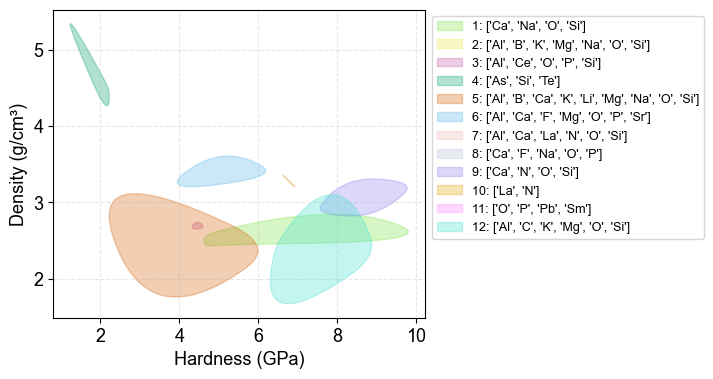

In [16]:
import os

# Loop over categories
for folder_name, prop_pairs in pairs_by_category.items():
    save_folder = f"gsc_for_all_with_label/{folder_name}"
#     save_folder = f"gsc_for_all/{folder_name}"
    os.makedirs(save_folder, exist_ok=True)

    for prop1, prop2 in prop_pairs:
#         for p1, p2 in [(prop1, prop2), (prop2, prop1)]:  # plot both directions
        print(f"Plotting {prop1} vs {prop2} into {folder_name}")
        try:
            plot_gsc(prop1, prop2, save_path=save_folder)  # Assuming plot_gsc can accept save_path
        except Exception as e:
            print(f"Failed to plot {prop1} vs {prop2}: {e}")


In [ ]:
'''
property_units = {
    'abbe number': 'non-dimensional',
    'activation energy': 'eV',
    'annealing point': 'K',
    'bulk modulus': 'GPa',
    'crystallization temperature': 'K',
    'density': 'g/cm³',
    'electric conductivity': 'Ω-¹·cm-¹',
    'fracture toughness': 'MPa.m½',
    'glass transition temperature': 'K',
    'hardness': 'GPa',
    'liquidus temperature': 'K',
    'melting temperature': 'K',
    'poisson ratio': 'non-dimensional',
    'refractive index': 'non-dimensional',
    'shear modulus': 'GPa',
    'softening point': 'K',
    'thermal expansion coefficient': 'K-¹',
    'youngs modulus': 'GPa'
}
'''

In [ ]:
# def plot_gsc(prop_1, prop_2, save_path="gsc_for_all"):
    
#     df = pd.read_csv("filtered_no_outliers_2.csv")  # Uncomment if loading externally

#     # Extract relevant columns
#     oxide_columns = [col for col in df.columns if col not in ['Proxy_ID', 'Refractive index', 'Abbe number', 'Property_Unit', 'density',
#            'Electric conductivity', 'Glass transition temperature',
#            'Crystallization temperature', 'Activation energy', 'Youngs modulus',
#            'Melting temperature', 'Thermal expansion coefficient',
#            'Softening point', 'Poisson ratio', 'Bulk modulus', 'Annealing point',
#            'Shear modulus', 'Hardness', 'Liquidus temperature',
#            'Fracture toughness']]

#     df[oxide_columns] = df[oxide_columns].apply(pd.to_numeric, errors='coerce')

#     df_filtered = df[['Proxy_ID', prop_1, prop_2] + oxide_columns].copy()
#     df_filtered = df_filtered[(df_filtered[prop_1] > 0) & (df_filtered[prop_2] > 0)]
#     # df_filtered = df_filtered[df_filtered['Bulk modulus'] > 0]

#     # Define composition families based on non-zero oxide components
#     df_filtered['family'] = df_filtered[oxide_columns].apply(lambda row: str(sorted(row[row > 0].index.tolist())), axis=1)

#     # Select the top 10 most frequent glass composition families
#     top_families = df_filtered['family'].value_counts().loc[lambda x: x.index != '[]'].head(13)
#     print(len(top_families))
#     df_top = df_filtered[df_filtered['family'].isin(top_families.index)]
    
#     df_top.to_csv(f'{prop_1}_{prop_2}.csv')

#     # Print elements in each family along with frequency
# #     print("Composition Families and Their Frequency:")
# #     for family, freq in top_families.items():
# #         print(f"{family}: {freq} occurrences")


#     # Colorblind-friendly colors
#     colors = [
#         "#7AE43F",  # Orange (Family 1)
#         "#F0E442",  # Bright Yellow (Family 4)
#         "#C556A4",  # Reddish Purple (Family 7)
#         "#009E73",  # Bluish Green (Family 3, unchanged)
#         "#D55E00",  # Vermillion (Family 6)
#         "#56B4E9",  # Sky Blue (Family 5)
#         "#EFB4B3",  # Wine Red (Family 2)
#         "#999999",  # Grey (Family 8)
#         "#897FF1",  # Dark Purple (Family 10)
#         "#E69F00",  # Saddle Brown (Family 9)
#         "#ff80ff",
#         "#de6e56",
#         "#b3bfd1",   
#     ] #tc_den, hard_den
    
# #     colors = [
# #         "#7AE43F",  # Orange (Family 1)
# #         "#F0E442",  # Bright Yellow (Family 4)
# #         "#C556A4",  # Reddish Purple (Family 7)
# #         "#009E73",  # Bluish Green (Family 3, unchanged)
# #         "#56B4E9",  # Vermillion (Family 6)
# #         "#D55E00",  # Sky Blue (Family 5)
# #         "#EFB4B3",  # Wine Red (Family 2)
# #         "#b3bfd1",  # Grey (Family 8)
# #         "#E69F00",  # Dark Purple (Family 10)
# #         "#897FF1",  # Saddle Brown (Family 9)
# #         "#ff80ff",
# #         "#de6e56",
# #         "#999999",   
# #     ] # tc_tg
    
# #     colors = [
# #         "#E6D800",  # Bright Yellow (Family 4)
# #         "#C556A4",  # Reddish Purple (Family 7)
# #         "#009E73",  # Bluish Green (Family 3, unchanged)
# #         "#ff80ff",
# #         "#56B4E9",  # Sky Blue (Family 5)
# #         "#7AE43F",  # Orange (Family 1)
# #         "#D55E00",  # Vermillion (Family 6)
# #         "#EFB4B3",  # Wine Red (Family 2)
# #         "#999999",  # Grey (Family 8)
# #         "#897FF1",  # Dark Purple (Family 10)
# #         "#E69F00",  # Saddle Brown (Family 9)
# #         "#de6e56",
# #         "#b3bfd1"
        
# #     ] #for tg_tm, den_ym

#     plot_idx = 0  # New counter
#     plt.figure(figsize=(4.8, 4)) #4.5, 4
#     plt.rcParams['font.family'] = 'Arial'
#     plt.rcParams['font.size'] = 13
#     for i, (family, freq) in enumerate(top_families.items()):
#         if i in  [7]: #for hard_den 7, for crys_den 11, 1 for tc_tg
#             continue
#         mask = df_top['family'] == family
#         points = df_top.loc[mask, [prop_1, prop_2]].values

#         unique_points = np.unique(points, axis=0)
#         if len(unique_points) < 3:
#             print(f"Skipping Family {i+1}: fewer than 3 unique points, Convex Hull cannot be formed.")
#             continue

#         if np.ptp(unique_points[:, 0]) == 0 or np.ptp(unique_points[:, 1]) == 0:
#             print(f"Skipping Family {i+1}: all points are aligned along one axis, Convex Hull cannot be formed.")
#             continue

#         try:
#             hull = ConvexHull(unique_points)
#             hull_points = unique_points[hull.vertices]
#             hull_points = np.vstack([hull_points, hull_points[0]])

#             point_density = len(unique_points) / (np.ptp(unique_points[:, 0]) * np.ptp(unique_points[:, 1]))
#             smoothing_factor = max(0.3, min(1.0, 1.0 / np.log1p(point_density)))

#             print(f'Family {family} {i} -->{len(unique_points)} smoothing_factor {smoothing_factor}')

#             tck, _ = splprep([hull_points[:, 0], hull_points[:, 1]], k=2, s=smoothing_factor, per=True)
#             smooth_hull = splev(np.linspace(0, 1, 100), tck)

#             plt.fill(smooth_hull[0], smooth_hull[1], color=colors[plot_idx % len(colors)], alpha=0.3, label=f"{family}")

# #             # Calculate center and annotate family number
# #             center_x = np.mean(hull_points[:, 0])
# #             center_y = np.mean(hull_points[:, 1])
# #             plt.text(center_x, center_y, f"{plot_idx+1}", fontsize=11, weight='bold', ha='center', va='center')
            
#             plot_idx += 1  # Increment only if plot is successful
#         except Exception as e:
#             print(f"Error computing Convex Hull for Family {i+1}: {e}")




# # #     Apply improved axis settings
# #     plt.xlim(min(df_top[f"{prop_1}"]) * 0.95, max(df_top[f"{prop_1}"]) * 1.05)
# #     plt.ylim(min(df_top[f"{prop_2}"]) * 0.95, max(df_top[f"{prop_2}"]) * 1.05)
# #     plt.ylim(2, 6, 1)
# #     plt.ylim(0, max(df_top['Youngs modulus']) * 1.05)

#     plt.xlabel(f"{prop_1.title()} (GPa)")
#     plt.ylabel(f"{prop_2.title()} (g/cm³)")
# #     plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
#     # plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
#     plt.grid(True, linestyle='--', alpha=0.3)
# #     plt.savefig(os.path.join(save_path, f'{prop_1}_{prop_2}.png'), dpi=900, bbox_inches='tight')
# #     plt.show()